<a href="https://colab.research.google.com/github/RogerVin1/PA3_Deep_Learning/blob/main/PA3_DL.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# PA3 — Poucos rótulos (Trilha C: professor–aluno)

**Dados:** ENA24, 21 espécies de armadilha fotográfica, 5 rótulos por classe (105) e pool sem rótulo.

Todo o código está em `pa3/` e `scripts/`. As células abaixo trazem o comando de cada etapa (comentado, para não retreinar) e mostram os resultados salvos em `results/`.

## Preparação do ambiente

In [37]:
%cd /content
!test -d PA3_Deep_Learning || git clone -q https://github.com/RogerVin1/PA3_Deep_Learning.git
%cd /content/PA3_Deep_Learning
!pip -q install -r requirements.txt

/content
/content/PA3_Deep_Learning


In [38]:
!pip -q install gdown
!mkdir -p /content/data
!test -d /content/data/pa3_dados || (cd /content/data && gdown 1g7FGqtXOk_ziNKBwQAk8BxjPOaPCnbui -O pa3_dados.zip && unzip -q -o pa3_dados.zip)
!ls /content/data/pa3_dados | head

classes.csv
images
labels
LEIAME.md


In [39]:
import json
import sys
from pathlib import Path

import pandas as pd
from IPython.display import Image, display

sys.path.insert(0, "/content/PA3_Deep_Learning")
DATA = "/content/data/pa3_dados"
pd.set_option("display.width", 160)

def jl(caminho):
    return json.load(open(caminho))

def mostrar(*caminhos, largura=420):
    for c in caminhos:
        print(c)
        display(Image(filename=c, width=largura))

## Verificações iniciais

In [40]:
from pa3.data import check_splits, find_root, ids_have_extension, load_split, read_classes
from pa3.models import build_model, check_param_budget, count_params

root = find_root(DATA)
classes = read_classes(root)
s = {n: load_split(root, n, classes) for n in ["train", "rotulos_1", "rotulos_5", "rotulos_20", "val", "test_public"]}
print(len(classes), "classes |", {n: len(v) for n, v in s.items()})
check_splits(s["train"], s["rotulos_5"], s["val"], s["test_public"])
print("sem vazamento entre train / rótulos / val / test_public")

for arch, pre in [("small_cnn", False), ("resnet18", True)]:
    m = build_model(arch, len(classes), pretrained=pre)
    print(f"{arch:10s} pretrained={pre!s:5}  {count_params(m):,} parâmetros  (≤ 12 M: {check_param_budget(m) <= 12_000_000})")

21 classes | {'train': 6505, 'rotulos_1': 21, 'rotulos_5': 105, 'rotulos_20': 420, 'val': 202, 'test_public': 811}
sem vazamento entre train / rótulos / val / test_public
small_cnn  pretrained=False  2,359,285 parâmetros  (≤ 12 M: True)
resnet18   pretrained=True   11,187,285 parâmetros  (≤ 12 M: True)


## Parte 0
Dois classificadores treinados apenas com os 5 rótulos por classe

,modelo,parâmetros,época (val),F1 val,F1 test_public,acurácia test
0,CNN pequena do zero,"2,359,285",59,0.207,0.169,0.200
1,ResNet-18 pré-treinada,"11,187,285",15,0.381,0.418,0.439


results/part0/piso_b_b5_s0/curva_treino_val.png


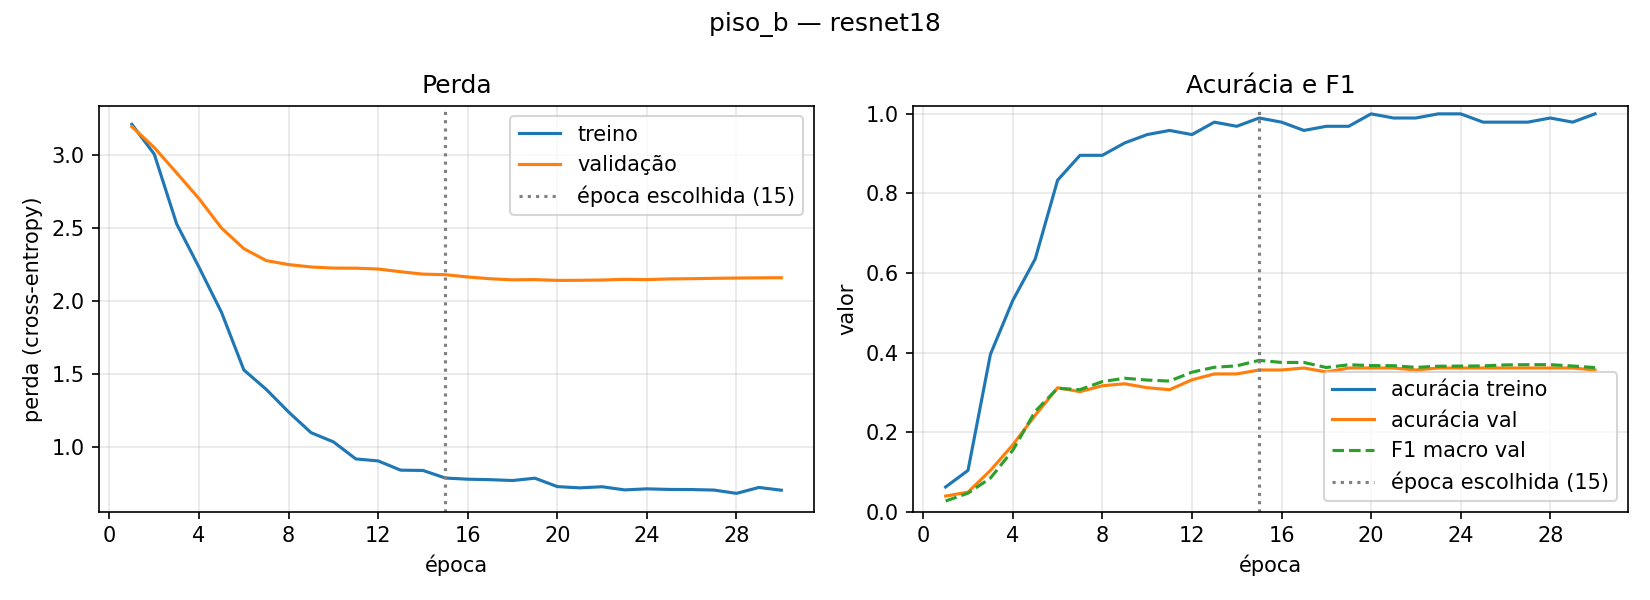

results/part0/piso_b_b5_s0/matriz_confusao_test_public.png


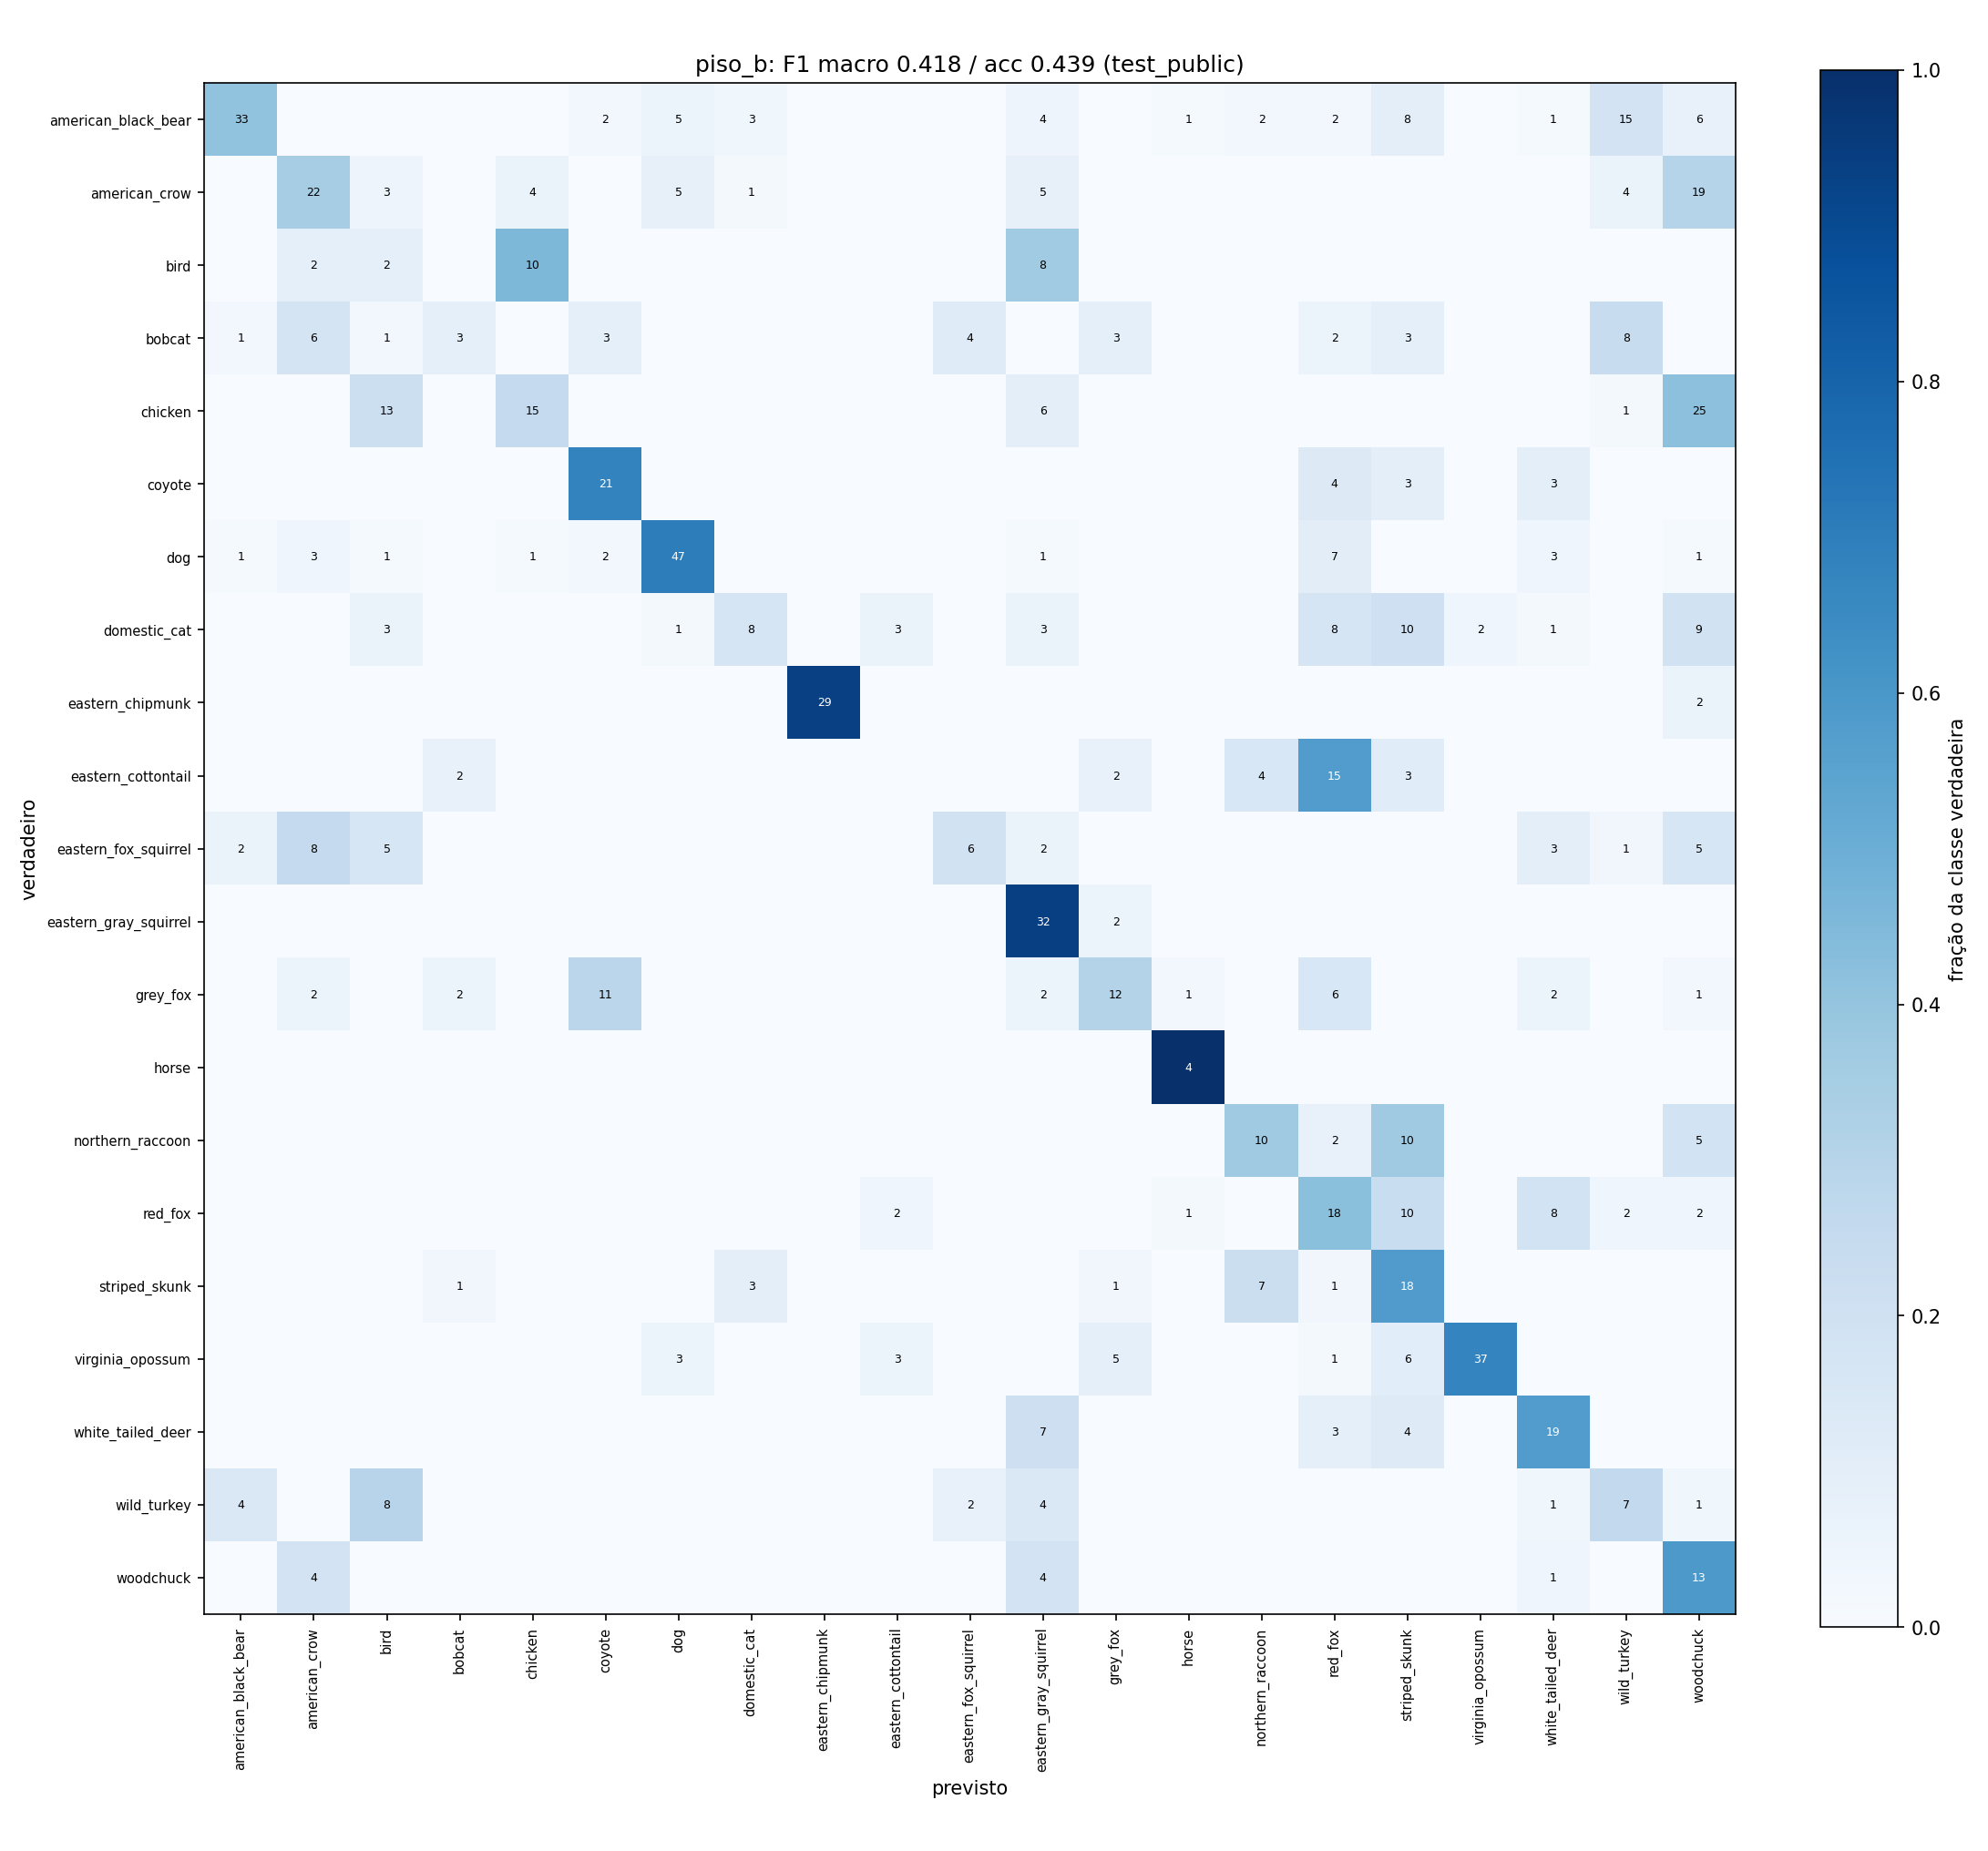

In [41]:
# Para reproduzir (≈ vários minutos na T4):
# !python scripts/part0_floor.py --data {DATA} --budget 5 --seed 0

linhas = []
for tag, nome in [("piso_a", "CNN pequena do zero"), ("piso_b", "ResNet-18 pré-treinada")]:
    m = jl(f"results/part0/{tag}_b5_s0/metrics.json")
    linhas.append({"modelo": nome, "parâmetros": f"{m['params']:,}", "época (val)": m["best_epoch"],
                   "F1 val": round(m["val"]["f1_macro"], 3), "F1 test_public": round(m["test_public"]["f1_macro"], 3),
                   "acurácia test": round(m["test_public"]["acc"], 3)})

display(pd.DataFrame(linhas))
mostrar("results/part0/piso_b_b5_s0/curva_treino_val.png", "results/part0/piso_b_b5_s0/matriz_confusao_test_public.png")

Com tão poucos rótulos, a CNN treinada do zero quase não aprende (F1 0,17), enquanto a ResNet-18 pré-treinada noImageNet chega a 0,42.

## Parte 1 — Trilha C: professor–aluno
**Professor:** BioCLIP 2 (pesos abertos, MIT), usado zero-shot com prompts de nome comum e científico.
Ele rotula as 6.505 imagens do `train` e nunca vê o `val`.

**Aluno:** ResNet-18 (11,19 M parâmetros) treinada nesses pseudo-rótulos junto com os 105 rótulos verdadeiros.

,onde,F1 macro,acurácia
0,test_public (811 imagens),0.668,0.673
1,105 imagens rotuladas,0.689,0.695


Confiança média do professor nos pseudo-rótulos do train: 0.805
Classes mais atribuídas pelo professor: {'woodchuck': 656, 'american_crow': 630, 'virginia_opossum': 608, 'american_black_bear': 584} | total: 6505

Matriz de confusão do professor = matriz de ruído dos pseudo-rótulos:
results/part1/bioclip2/matriz_confusao_professor.png


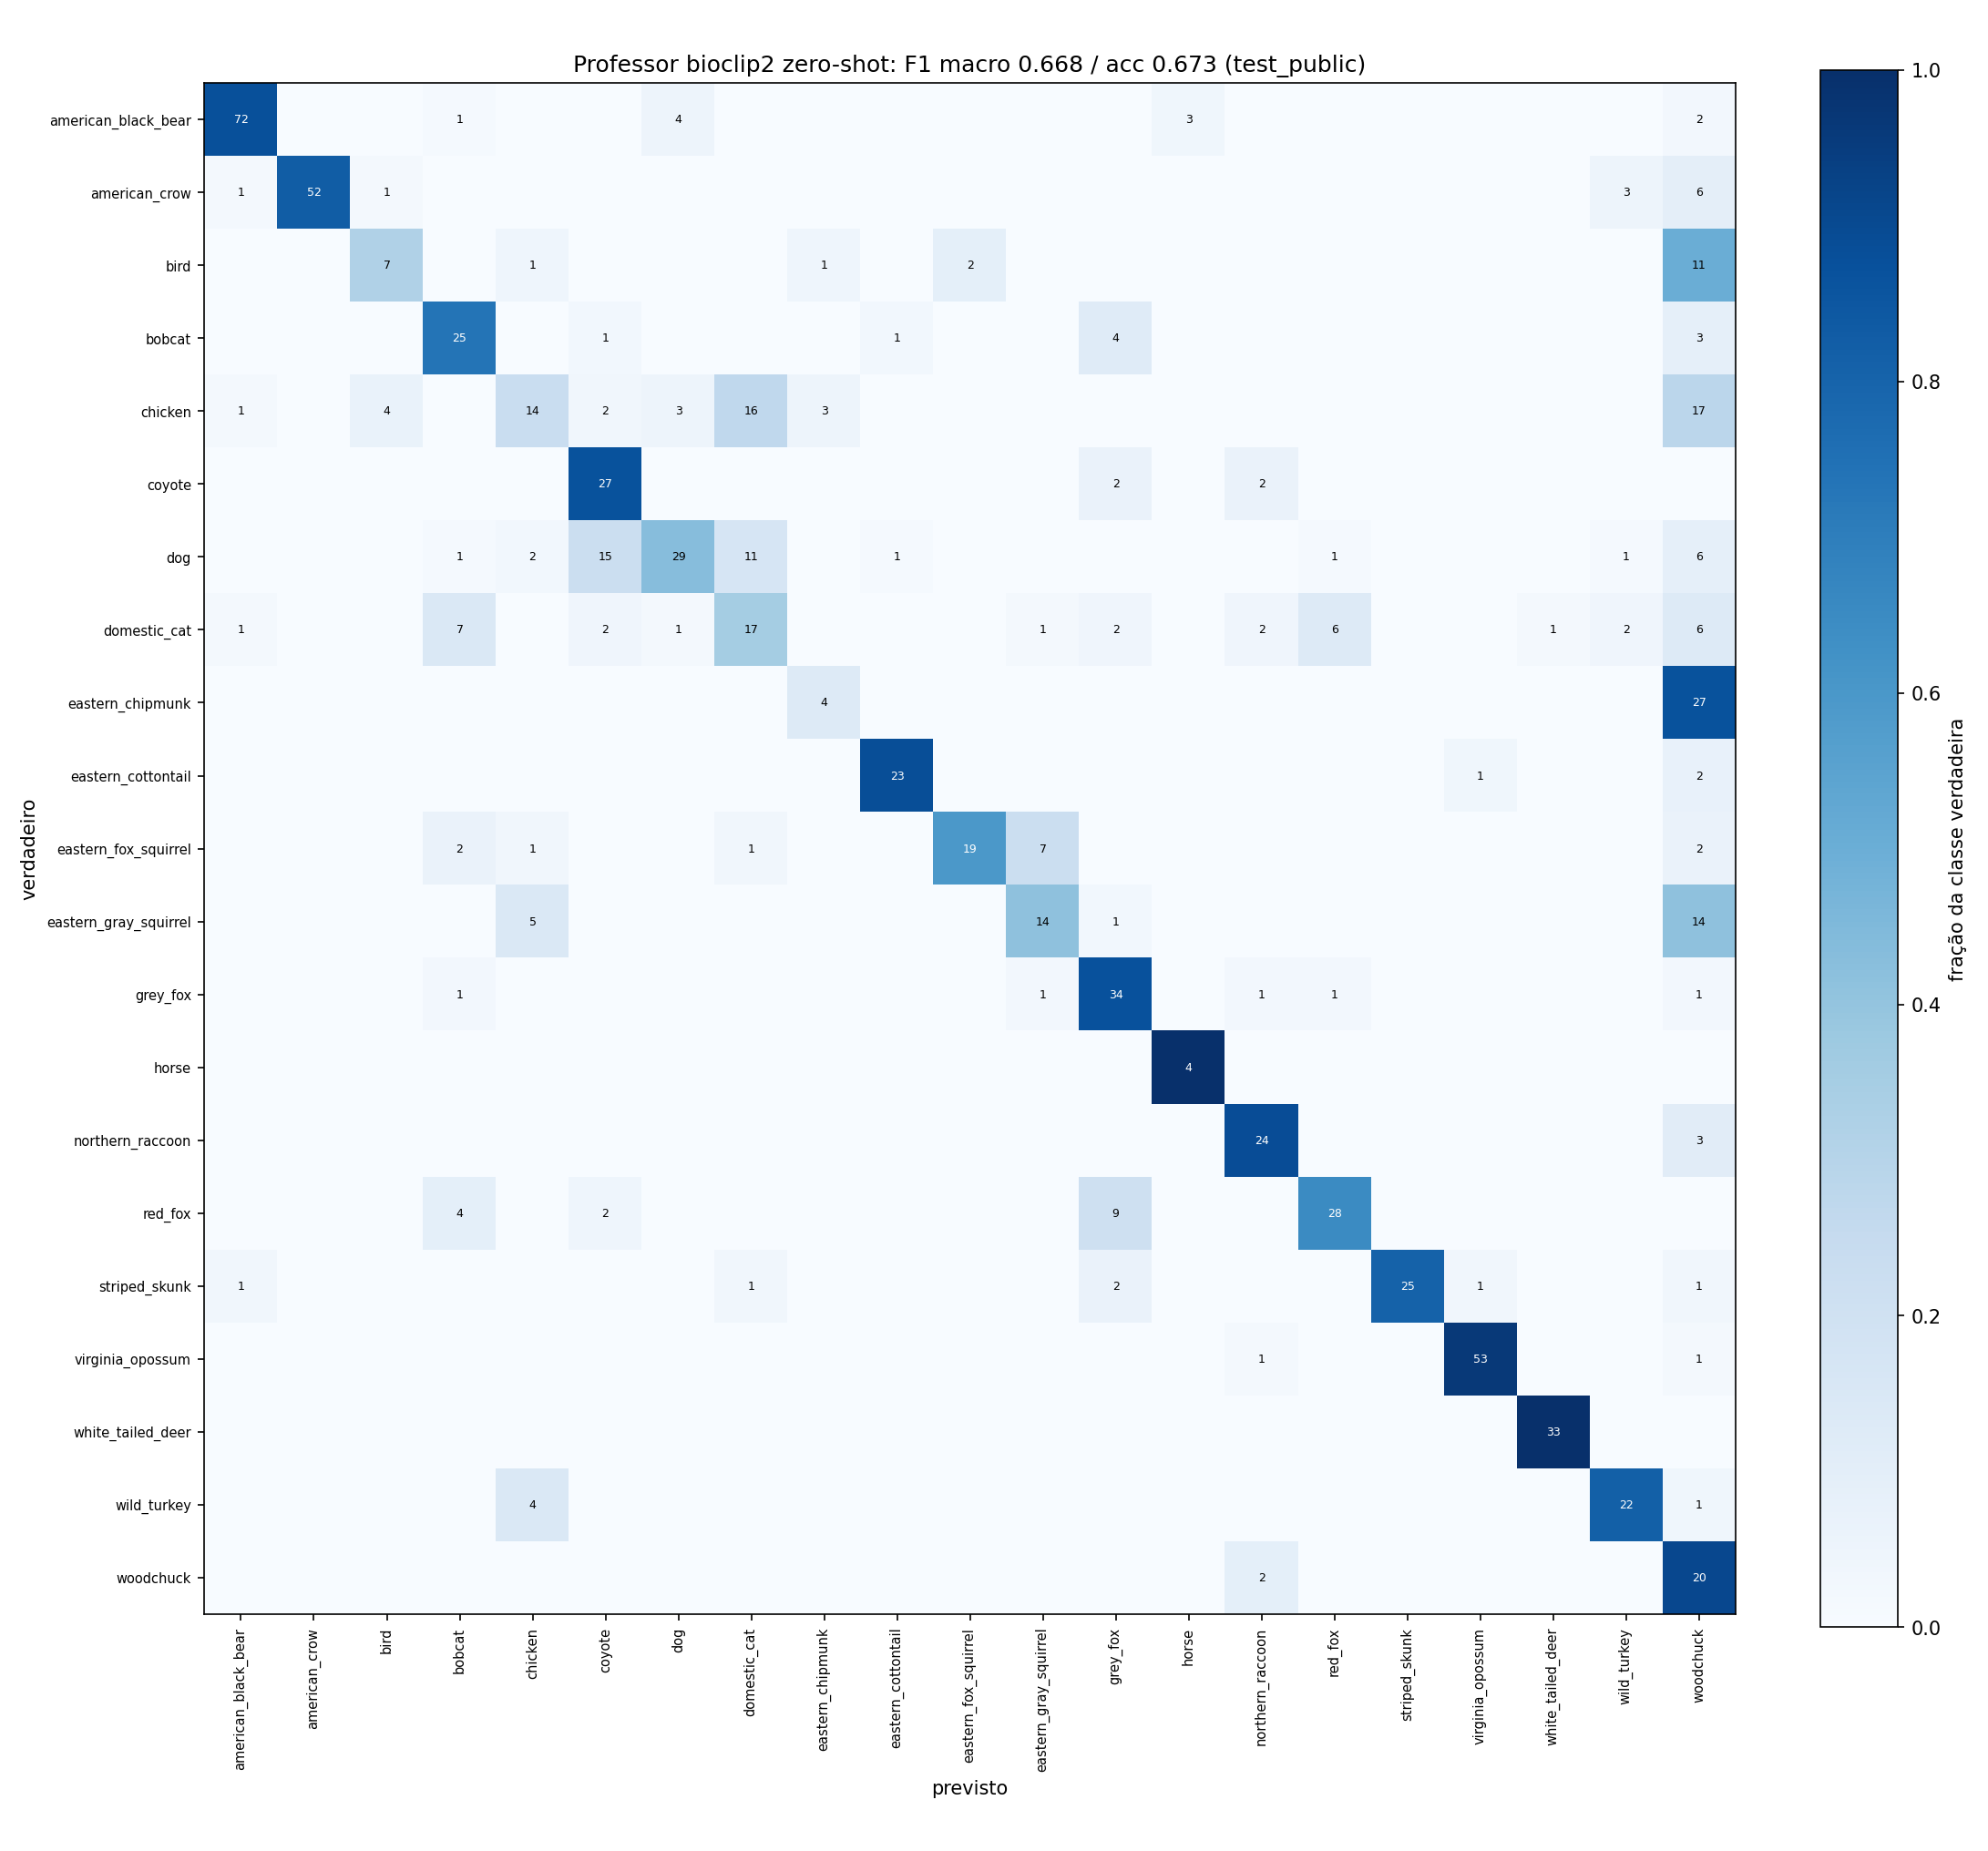

In [42]:
# Para reproduzir (calcula os embeddings do train e do test_public, nunca do val):
# !python scripts/part1_teacher.py --data {DATA} --teacher bioclip2

m = jl("results/part1/bioclip2/metrics.json")
tp, lab = m["test_public"], m["rotulos_5"]
display(pd.DataFrame([
    {"onde": "test_public (811 imagens)", "F1 macro": round(tp["f1_macro"], 3), "acurácia": round(tp["acc"], 3)},
    {"onde": "105 imagens rotuladas", "F1 macro": round(lab["f1_macro"], 3), "acurácia": round(lab["acc"], 3)}]))

print("Confiança média do professor nos pseudo-rótulos do train:", round(m["confianca_media_train"], 3))
pr = pd.Series(m["pseudo_rotulos_por_classe"]).sort_values(ascending=False)
print("Classes mais atribuídas pelo professor:", pr.head(4).to_dict(), "| total:", int(pr.sum()))
print("\nMatriz de confusão do professor = matriz de ruído dos pseudo-rótulos:")
mostrar("results/part1/bioclip2/matriz_confusao_professor.png", largura=700)

In [43]:
# Para reproduzir:
# !python scripts/part1_erros_professor.py --data {DATA} --teacher bioclip2

print("Acurácia do professor por grupo (test_public):")
display(pd.read_csv("results/part1/bioclip2/erros_por_grupo.csv"))

print("Pares mais confundidos (verdadeira -> prevista):")
display(pd.read_csv("results/part1/bioclip2/pares_confundidos.csv"))

Acurácia do professor por grupo (test_public):


,grupo,n,acuracia,previsto_woodchuck(%)
0,todas,811,0.673,15.2
1,noite (cinza),391,0.803,3.3
2,dia (colorida),420,0.552,26.2
3,terço mais escuro,271,0.823,2.2
4,terço médio,269,0.520,19.7
5,terço mais claro,271,0.675,23.6
6,classes pequenas,275,0.429,36.0
7,classes grandes,536,0.799,4.5


Pares mais confundidos (verdadeira -> prevista):


,verdadeira,prevista,n,fracao_da_classe
0,eastern_chipmunk,woodchuck,27,0.87
1,chicken,woodchuck,17,0.28
2,chicken,domestic_cat,16,0.27
3,dog,coyote,15,0.22
4,eastern_gray_squirrel,woodchuck,14,0.41
5,bird,woodchuck,11,0.50
6,dog,domestic_cat,11,0.16
7,red_fox,grey_fox,9,0.21
8,domestic_cat,bobcat,7,0.15
9,eastern_fox_squirrel,eastern_gray_squirrel,7,0.22


**Onde o professor erra de forma sistemática**
- **Animais pequenos, principalmente de dia:** acurácia 0,43 nas classes pequenas contra 0,80 nas grandes.
  Imagens em cinza (noite) são mais fáceis (0,80) que as coloridas (0,55); isso está misturado com a
  composição das classes (animais grandes aparecem mais à noite), então não é um efeito isolado.
- **`woodchuck` é como se fosse um "ralo":** recebe 15% das previsões do professor. `eastern_chipmunk → woodchuck` em 87% dos
  casos, `eastern_gray_squirrel` 41%, `bird` 50%, `chicken` 28%.
- **Classes parecidas:** `dog → coyote`, `red_fox → grey_fox`, `eastern_fox_squirrel → eastern_gray_squirrel`,
  `domestic_cat → bobcat`.

## Parte 1 — O aluno e o tratamento do ruído
O professor tem ruído sistemático (seção acima). Comparamos quatro formas de treinar o aluno, escolhendo pelo F1 no `val`:

1. `aluno_hard`: pseudo-rótulo duro (argmax do professor).
2. `aluno_soft_T1`: rótulos suaves (softmax do professor, temperatura 1).
3. `aluno_soft_cal`: rótulos suaves de um **professor melhorado com os 105 rótulos** (viés por classe + temperatura,
   `pa3/calibrate.py`; o λ é escolhido por validação cruzada dentro dos 105 rótulos, nunca no `val`).
4. `aluno_soft_cal_foto`: como (3), com augmentação fotométrica forte (mais variação de brilho e imagens em cinza).


In [44]:
# Para reproduzir (cada rodada ≈ alguns minutos na T4; precisa dos embeddings do professor):
# !python scripts/part1_student.py --data {DATA} --budget 5 --seed 0 --targets hard
# !python scripts/part1_student.py --data {DATA} --budget 5 --seed 0 --targets soft --temperature 1.0 --variant aluno_soft_T1
# !python scripts/part1_student.py --data {DATA} --budget 5 --seed 0 --targets soft --calibrate
# !python scripts/part1_student.py --data {DATA} --budget 5 --seed 0 --targets soft --calibrate --photo-aug forte

NOMES = {"aluno_hard": "1. duros",
         "aluno_soft_T1": "2. suaves (T=1)",
         "aluno_soft_cal": "3. suaves + professor calibrado",
         "aluno_soft_cal_foto": "4. (3) + augmentação fotométrica"}

curva = pd.read_csv("curva_orcamento.csv")
curva = curva[(curva.orcamento == 5) & (curva.seed == 0)].set_index("metodo")
piso_b = jl("results/part0/piso_b_b5_s0/metrics.json")

linhas = [{"método": "Piso (ResNet-18, 105 rótulos)", "F1 val": round(piso_b["val"]["f1_macro"], 3),
           "F1 test_public": round(curva.loc["piso", "f1_macro"], 3), "acurácia test": round(curva.loc["piso", "acuracia"], 3),
           "época escolhida": piso_b["best_epoch"], "época de menor loss no val": piso_b["memorizacao"]["epoch_min_val_loss"]},
          {"método": "Professor zero-shot (BioCLIP 2)", "F1 val": "—", "F1 test_public": round(curva.loc["professor", "f1_macro"], 3),
           "acurácia test": round(curva.loc["professor", "acuracia"], 3), "época escolhida": "—", "época de menor loss no val": "—"},
          {"método": "Professor melhorado (viés + T)", "F1 val": "—", "F1 test_public": round(curva.loc["professor_cal", "f1_macro"], 3),
           "acurácia test": round(curva.loc["professor_cal", "acuracia"], 3), "época escolhida": "—", "época de menor loss no val": "—"}]

for v, nome in NOMES.items():
    a = jl(f"results/part1/aluno/{v}_b5_s0/metrics.json")
    linhas.append({"método": "Aluno " + nome, "F1 val": round(a["val"]["f1_macro"], 3),
                   "F1 test_public": round(curva.loc[v, "f1_macro"], 3), "acurácia test": round(curva.loc[v, "acuracia"], 3),
                   "época escolhida": a["best_epoch"], "época de menor loss no val": a["memorizacao"]["epoch_min_val_loss"]})

tabela = pd.DataFrame(linhas)
display(tabela)
print("Referência (não é um limite): ResNet-18 do monitor com todos os rótulos = 0,686 de F1 macro.")

,método,F1 val,F1 test_public,acurácia test,época escolhida,época de menor loss no val
0,"Piso (ResNet-18, 105 rótulos)",0.381,0.418,0.439,15,20
1,Professor zero-shot (BioCLIP 2),—,0.668,0.673,—,—
2,Professor melhorado (viés + T),—,0.732,0.730,—,—
3,Aluno 1. duros,0.599,0.550,0.599,7,3
4,Aluno 2. suaves (T=1),0.62,0.568,0.605,8,3
5,Aluno 3. suaves + professor calibrado,0.642,0.652,0.678,10,3
6,Aluno 4. (3) + augmentação fotométrica,0.603,0.645,0.679,9,9


Referência (não é um limite): ResNet-18 do monitor com todos os rótulos = 0,686 de F1 macro.


**Leitura (escolha pelo `val`):** a melhor versão no `val` é a **(3) `aluno_soft_cal`** (F1 val 0,642), e é ela o aluno final.
Calibrar o professor com os 105 rótulos foi o que mais ajudou, os rótulos suaves sozinhos ajudaram pouco
(0,620 contra 0,599 no `val`, dentro do ruído de um `val` com 202 imagens). A augmentação fotométrica forte (4)
**piorou** o `val` (0,603) e, como a regra é decidir pelo `val`, foi descartada e fica registrada como experimento negativo.

**Memorização do ruído:** nas versões 1 a 3 a perda no `val` é mínima já na época 3 e depois sobe (o aluno passa a decorar os
pseudo-rótulos errados), embora o F1 no `val` continue melhorando devagar. Por isso a época é escolhida pelo F1 no `val`,
não pela perda.

**Resumo:** o aluno sai do piso 0,418 para **0,652** (test_public), perto do professor zero-shot (0,668) e do teto de referência (0,686),
mas abaixo do professor melhorado (0,732). Este último é só diagnóstico: o professor não faz parte do modelo entregue.

Aluno final: aluno_soft_cal | parâmetros: 11,187,285 | época: 10 | val F1: 0.642 | test_public F1: 0.652
Calibração do professor: λ = 0.001 | T = 1.09
results/part1/aluno/aluno_soft_cal_b5_s0/curva_treino_val.png


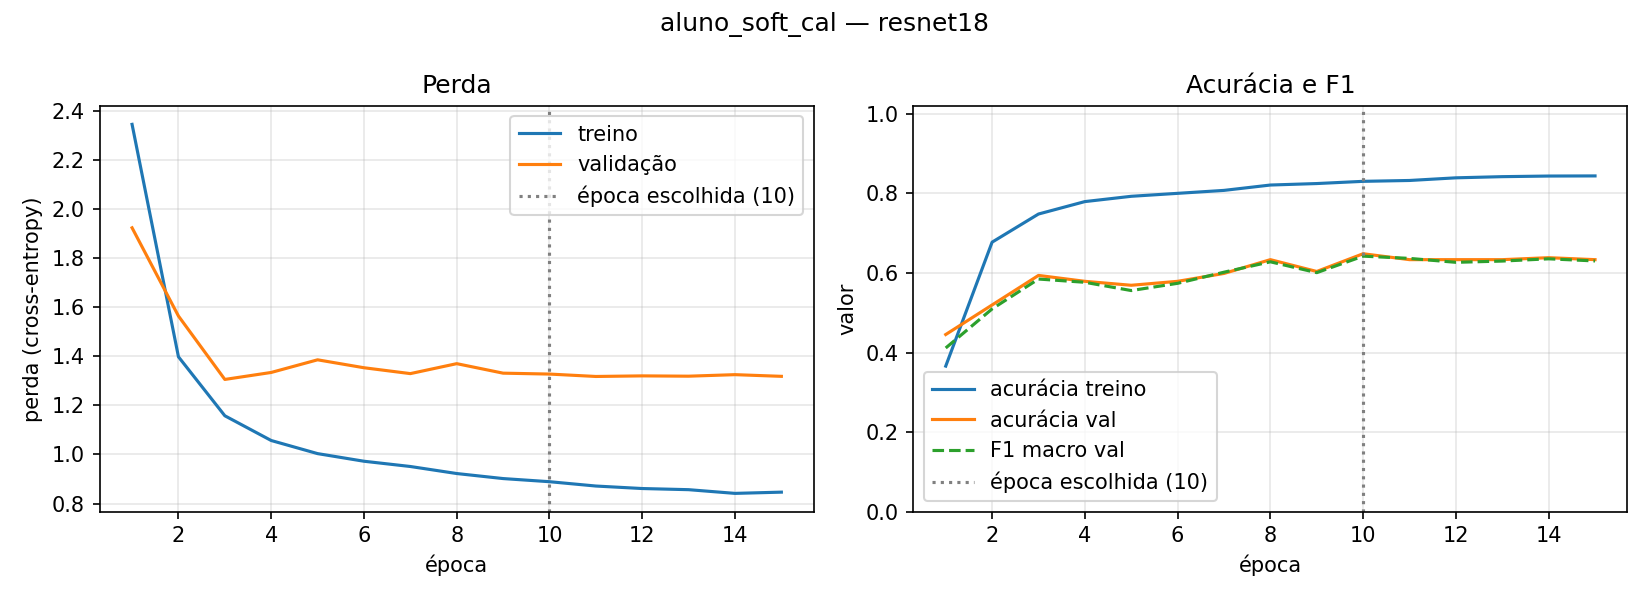

results/part1/aluno/aluno_soft_cal_b5_s0/matriz_confusao_test_public.png


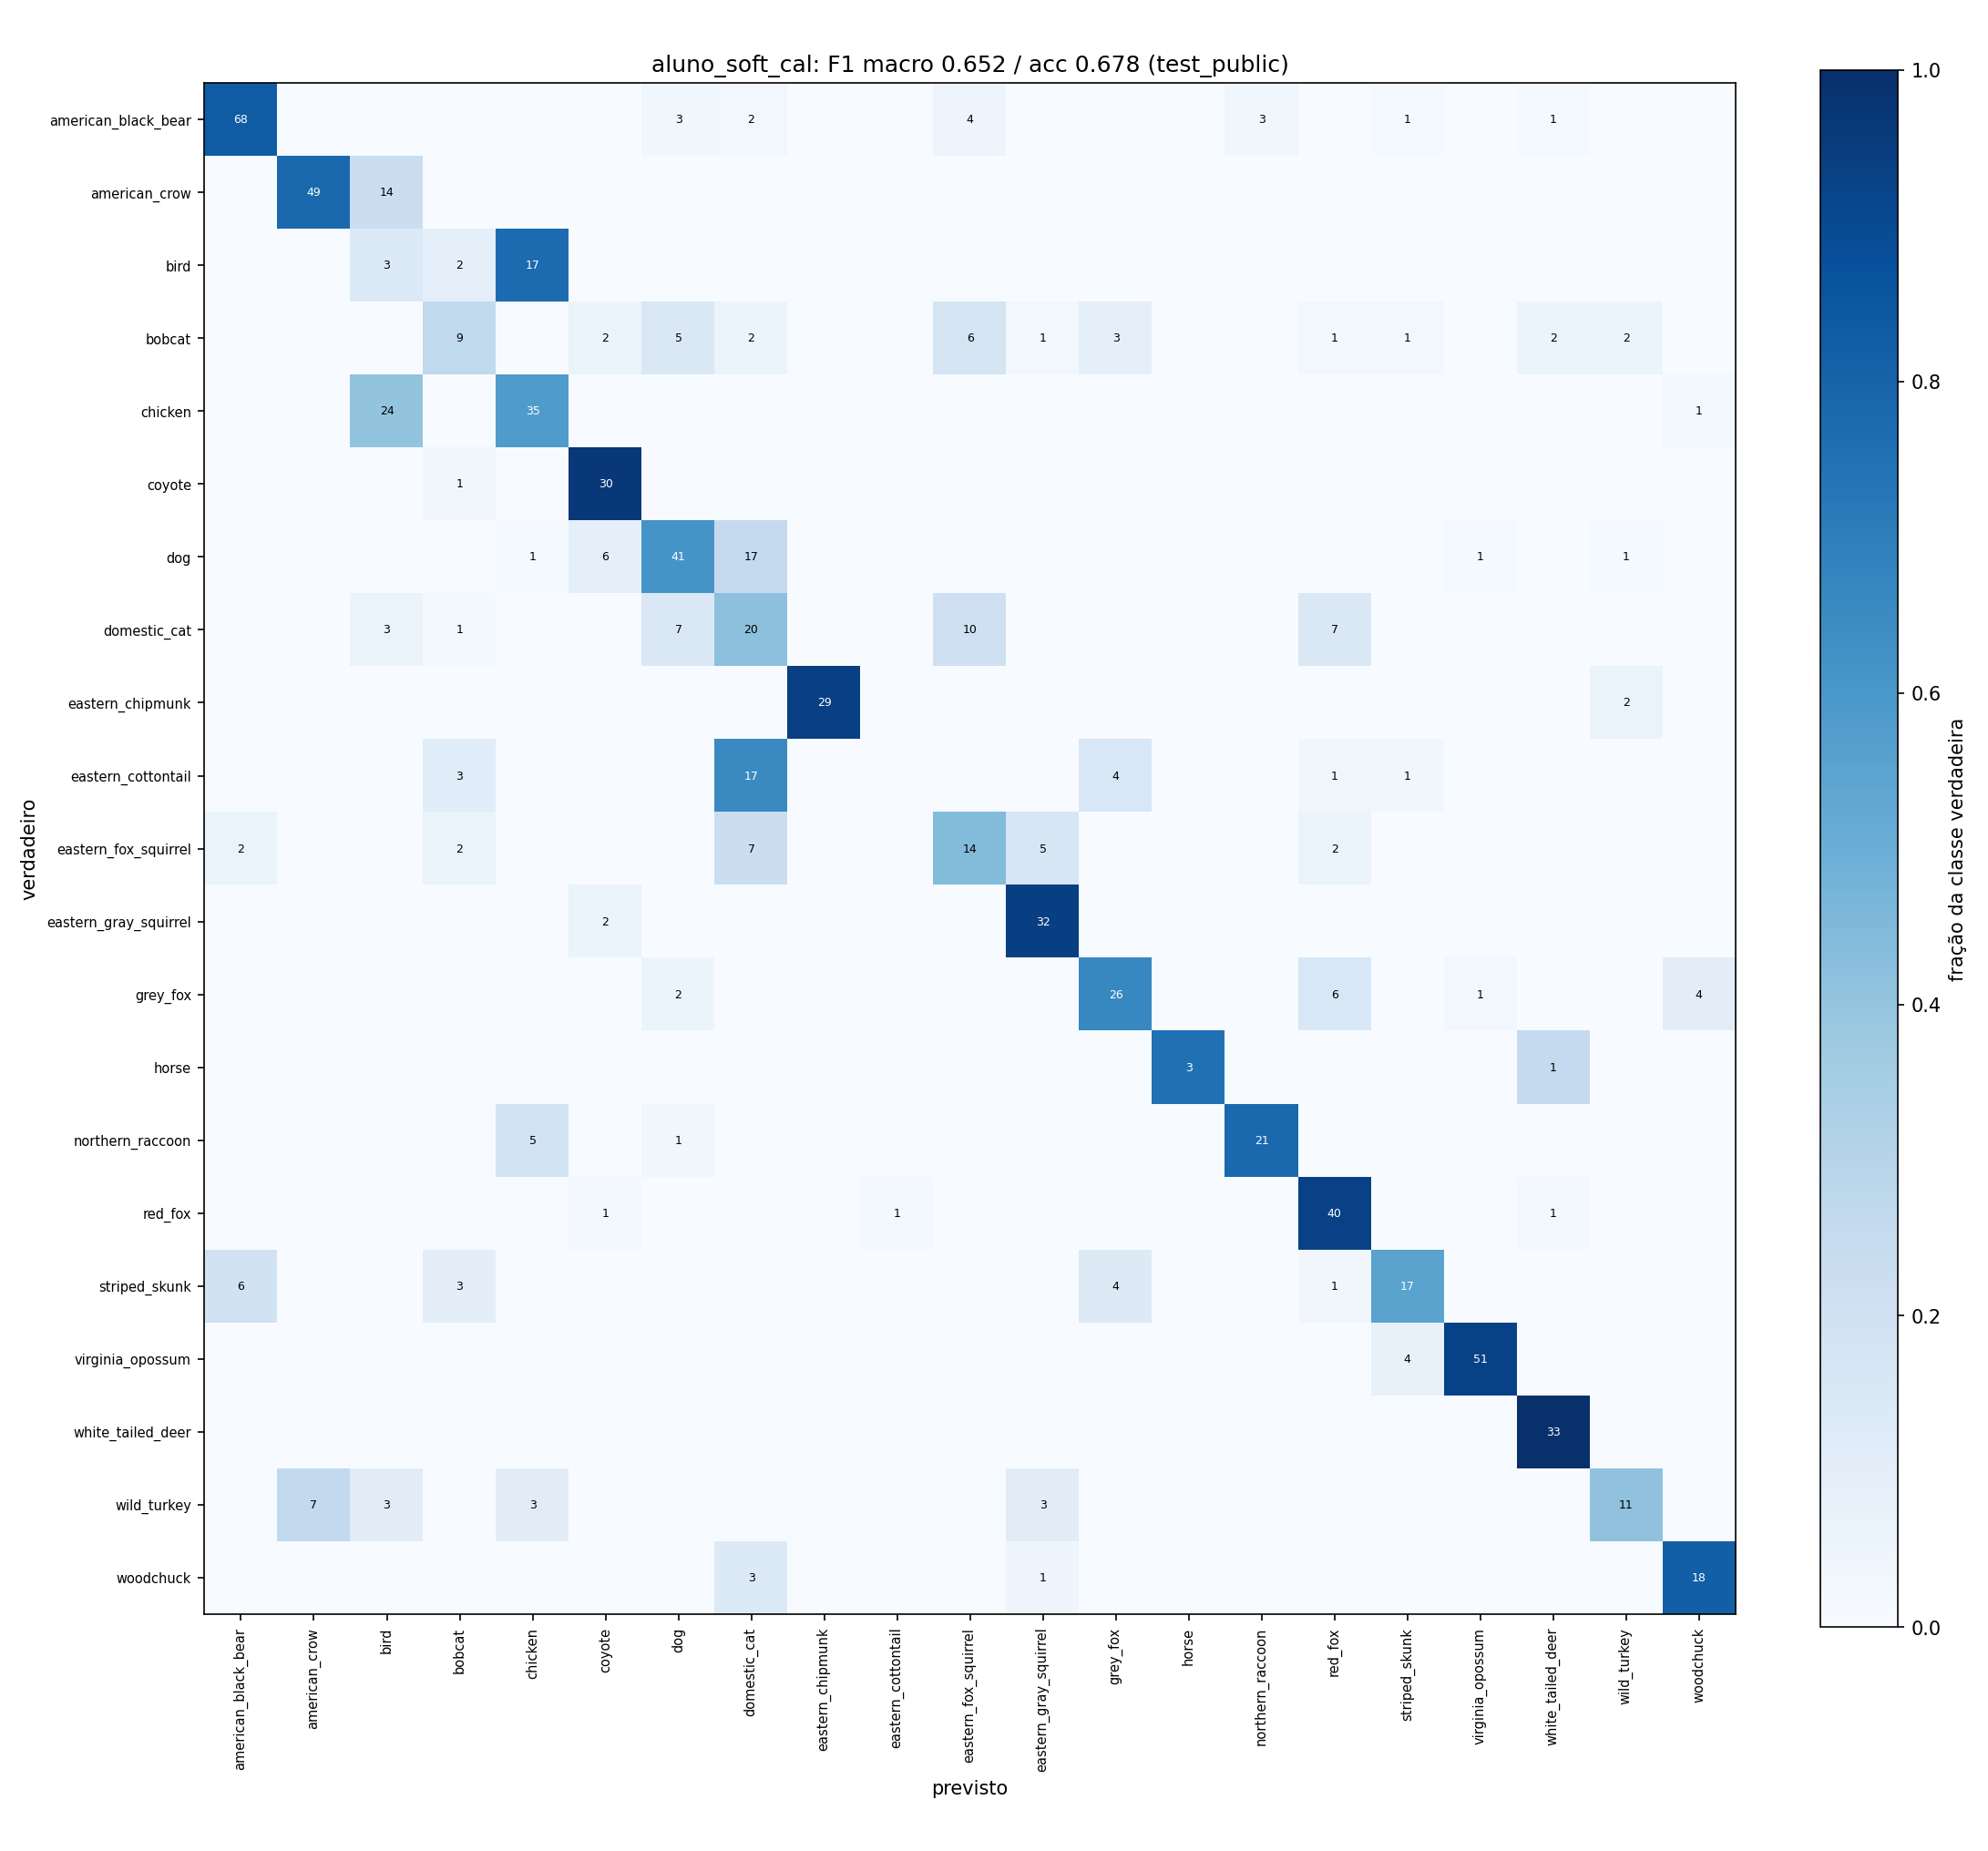

In [45]:
a = jl("results/part1/aluno/aluno_soft_cal_b5_s0/metrics.json")
print("Aluno final: aluno_soft_cal | parâmetros:", f"{a['params']:,}", "| época:", a["best_epoch"],
      "| val F1:", round(a["val"]["f1_macro"], 3), "| test_public F1:", round(a["test_public"]["f1_macro"], 3))

print("Calibração do professor: λ =", a["calibracao"]["lambda"], "| T =", round(a["calibracao"]["temperatura"], 2))
mostrar("results/part1/aluno/aluno_soft_cal_b5_s0/curva_treino_val.png",
        "results/part1/aluno/aluno_soft_cal_b5_s0/matriz_confusao_test_public.png", largura=520)

## Em quais classes o aluno vence o professor, e por quê?
F1 por classe no `test_public`: professor zero-shot, professor melhorado e aluno final (`aluno_soft_cal`).

In [46]:
a = jl("results/part1/aluno/aluno_soft_cal_b5_s0/metrics.json")
por_classe = pd.DataFrame({"professor (zero-shot)": a["f1_por_classe_professor"],
                           "professor melhorado": a["f1_por_classe_professor_cal"],
                           "aluno": a["f1_por_classe_aluno"]})
por_classe["aluno − professor"] = por_classe["aluno"] - por_classe["professor (zero-shot)"]
por_classe = por_classe.sort_values("aluno − professor", ascending=False).round(2)
display(por_classe)
print("Aluno melhor que o professor zero-shot em", int((por_classe["aluno − professor"] > 0.05).sum()), "classes (> 0,05);",
      "pior em", int((por_classe["aluno − professor"] < -0.05).sum()), "classes (< −0,05).")

,professor (zero-shot),professor melhorado,aluno,aluno − professor
eastern_chipmunk,0.21,0.53,0.97,0.76
woodchuck,0.28,0.56,0.80,0.52
eastern_gray_squirrel,0.49,0.59,0.84,0.35
chicken,0.32,0.39,0.58,0.26
coyote,0.68,0.82,0.83,0.16
horse,0.73,0.73,0.86,0.13
dog,0.56,0.59,0.65,0.09
red_fox,0.71,0.80,0.79,0.08
northern_raccoon,0.81,0.79,0.82,0.01
domestic_cat,0.36,0.40,0.34,-0.02


Aluno melhor que o professor zero-shot em 8 classes (> 0,05); pior em 8 classes (< −0,05).


**O aluno vence o professor** em `eastern_chipmunk` (0,21 → 0,97), `woodchuck` (0,28 → 0,80), `eastern_gray_squirrel` (0,49 → 0,84),
`chicken` (0,32 → 0,58) e, com ganhos menores, coyote, horse, dog e red_fox. São quase todas as classes que o
professor descarta no `woodchuck`. Contra o professor novo agora, o aluno ainda vence em eastern_chipmunk, woodchuck, eastern_gray_squirrel, chicken, horse e dog.

**Por quê (hipótese):** o professor zero-shot só vê "o que é essa espécie" e erra de forma sistemática nesses
roedores e aves pequenas. O aluno treina com as 6.505 imagens *do próprio domínio* (mesmas câmeras e fundos) mais os rótulos
verdadeiros, e aprende a separar essas classes por contexto e aparência locais que o professor não usa. Com rótulos suaves
de um professor calibrado, o ruído sistemático diminui e os rótulos verdadeiros ancoram essas classes.
As diferenças pequenas (dog, horse, red_fox) estão dentro do ruído, pois cada classe tem só 22 a 80 imagens no `test_public`.

**O aluno perde** em eastern_cottontail (0,90 → 0,00), bird, bobcat, eastern_fox_squirrel, wild_turkey e striped_skunk:
nelas o conhecimento de espécie do BioCLIP generaliza melhor do que o que o aluno aprende com poucas imagens.

## Diagnóstico: por que o aluno nunca acerta `eastern_cottontail`?
O professor acerta bem essa classe (F1 0,90) e seus pseudo-rótulos são bons, mas o aluno tem recall 0 no `test_public`
(0,60 no `val`, que tem só 10 coelhos).

In [47]:
# Para reproduzir:
# !python scripts/diagnose_class.py --data {DATA} --classe eastern_cottontail

display(pd.read_csv("results/part1/diagnostico/eastern_cottontail.csv"))

,grupo,n,brilho_medio,cinza(%),tamanho_mais_comum,tamanho(%),n_tamanhos
0,"train (eastern_cottontail, pseudo)",182,77.0,60,512x367,52,5
1,"val (eastern_cottontail, real)",10,75.7,100,512x367,70,2
2,"test (eastern_cottontail, real)",26,53.7,100,512x367,77,3
3,train (outras classes),400,90.2,56,512x367,44,4
4,test (outras classes),400,89.8,46,512x367,50,4


**O que o diagnóstico mostra:** os coelhos do `test_public` são mais escuros (brilho médio 54, contra 77 no `train` e 76 no `val`)
e todos em tons de cinza (noite), enquanto 40% dos coelhos do `train` são coloridos. O tamanho das imagens (câmera) é parecido,
então não é troca de câmera. Uma augmentação fotométrica forte (variante 4) **não resolveu** (continua em 0), então o deslocamento de
brilho sozinho não explica; a causa fica **em aberto**. Esse é um caso em que o `val` não avisa do problema.

## Pergunta: e se aparecer uma capivara?
Nosso método só conhece 21 classes e o softmax obriga qualquer imagem a cair em alguma delas. O que sinalizaria uma
imagem fora das classes:

- **Confiança baixa:** probabilidade máxima do softmax baixa (ou entropia alta), no aluno ou no professor.
- **Distância ao que o modelo conhece:** no professor, similaridade de cosseno máxima entre o embedding da imagem e os 21 textos
  de classe; no aluno, distância das features da penúltima camada às médias das classes.
- **Limite honesto:** o softmax costuma ser excessivamente confiante e joga o desconhecido num "ralo", como vimos com o `woodchuck`.
  A calibração com os rótulos ajuda, mas não garante; o limiar teria que ser escolhido no `val`, por exemplo rejeitando a fração menos confiante.